<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/06.%20Advanced%20Logistic%20Regression%20and%20Extensions/ch06_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 6: Advanced Logistic Regression and Extensions

Logistic regression predicts **qualitative** (categorical) outcomes by applying the logistic (sigmoid) function to a linear combination of features. This chapter extends the binary case from the ML course's earlier material into multiclass and multilabel classification, regularization (building directly on Ridge/Lasso from Chapter 5), and a full toolbox of classification evaluation metrics.

**What this notebook covers**

1. **Overview of logistic regression**: the sigmoid function, maximum likelihood, binary classification on the Breast Cancer dataset
2. **Multiclass classification**: one-vs-rest (OvR) vs. multinomial (softmax) logistic regression on the Iris dataset
3. **Regularization in logistic regression**: L2 (Ridge) and L1 (Lasso) penalties, the `C` hyperparameter, coefficient-shrinkage paths
4. **Multilabel classification**: training one classifier per label, label co-occurrence analysis
5. **Model evaluation metrics**: precision, recall, F1, ROC/AUC
6. **Practical exercises** (regularized logistic regression, multiclass evaluation, decision-boundary visualization)

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 6. The book's datasets and seed (`random_state=2024`) are reproduced; each recipe is extended with derivations, extra verification, and additional experiments beyond the book's own code.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_breast_cancer, load_iris, make_multilabel_classification, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, roc_curve, auc)
from sklearn.inspection import DecisionBoundaryDisplay

np.random.seed(2024)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"pandas version:       {pd.__version__}")

scikit-learn version: 1.9.1
NumPy version:        2.5.3
pandas version:       3.0.5


## 1. Overview of Logistic Regression

Linear regression predicts a continuous number; logistic regression predicts a **probability**. It does this by applying the **sigmoid function** to a linear combination of the features:

$$P(Y=1\mid X)=\sigma(z)=\frac{1}{1+e^{-z}},\qquad z=\beta_0+\beta_1x_1+\dots+\beta_px_p$$

Unlike OLS, there is no closed form for $\boldsymbol\beta$: it is found by **maximum likelihood estimation (MLE)**, maximising

$$\mathcal L(\boldsymbol\beta)=\prod_{i=1}^n P(Y=y_i\mid X_i)=\prod_{i=1}^n \sigma(z_i)^{y_i}(1-\sigma(z_i))^{1-y_i}$$

equivalently minimising the **negative log-likelihood** (log-loss / cross-entropy), typically with gradient-based solvers (`lbfgs`, `liblinear`, `saga`, ...). A record is classified as the positive class once $P(Y=1\mid X)>0.5$, equivalently $z>0$.

### 1.1 The sigmoid function, visualised

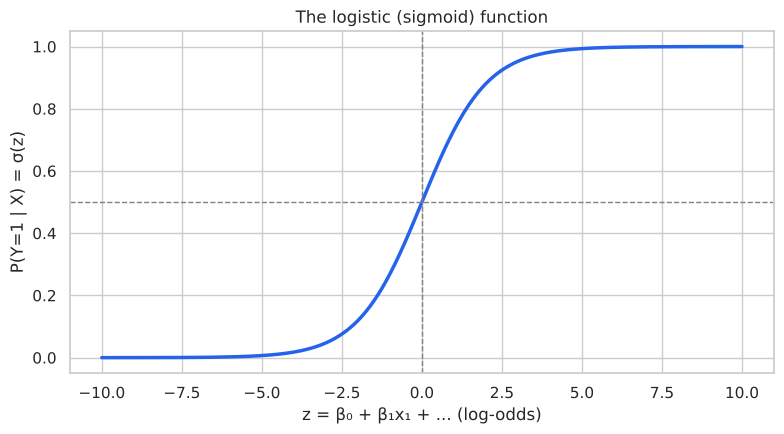

In [2]:
z = np.linspace(-10, 10, 400)
sigmoid = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(z, sigmoid, color="#2563eb", lw=2.5)
ax.axhline(0.5, color="grey", ls="--", lw=1)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_xlabel("z = β₀ + β₁x₁ + ... (log-odds)")
ax.set_ylabel("P(Y=1 | X) = σ(z)")
ax.set_title("The logistic (sigmoid) function")
plt.tight_layout()
plt.show()

**Log-odds.** The inverse of the sigmoid is the **logit**: $z=\ln\!\big(\tfrac{p}{1-p}\big)$, the log of the odds of the positive class. This is why logistic regression's decision boundary is linear in the *log-odds* scale even though the probability curve itself is S-shaped: $z$ is a straight line in the features, it is only $\sigma(z)$ that bends it into $[0,1]$.

### 1.2 Binary classification on the Breast Cancer dataset

As in the book: `load_breast_cancer()`, an 80/20 split (we use the book's own `random_state=2024`), and a plain `LogisticRegression`.

In [3]:
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = data.feature_names
class_names = ['Malignant', 'Benign']  # sklearn encodes malignant=0, benign=1

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    df[feature_names], df['target'], test_size=0.2, random_state=2024)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Class balance (train): {np.bincount(y_train)} -> {np.bincount(y_train) / len(y_train)}")

Train: (455, 30), Test: (114, 30)
Class balance (train): [166 289] -> [0.36483516 0.63516484]


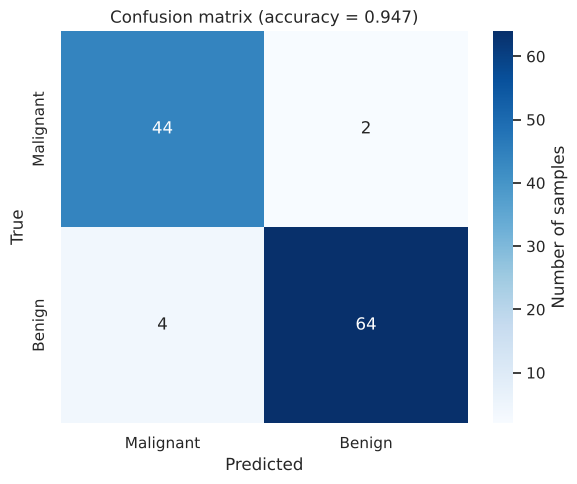

Accuracy: 0.9474

              precision  recall  f1-score  support
Malignant        0.9170  0.9570    0.9360  46.0000
Benign           0.9700  0.9410    0.9550  68.0000
accuracy         0.9470  0.9470    0.9470   0.9470
macro avg        0.9430  0.9490    0.9460 114.0000
weighted avg     0.9480  0.9470    0.9480 114.0000


In [4]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Number of samples'}, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'Confusion matrix (accuracy = {accuracy:.3f})')
plt.tight_layout()
plt.show()

report_df = pd.DataFrame(classification_report(y_test, y_pred, target_names=class_names, output_dict=True)).transpose()
print(f"Accuracy: {accuracy:.4f}\n")
print(report_df.round(3))

Even with default settings the model separates malignant from benign tumours very well. As the book asks: *is accuracy always the best metric here?* No — in a medical screening context, missing a malignant case (a **false negative**) is far costlier than a false alarm, so **recall on the malignant class** usually matters more than overall accuracy. We confirm this concretely below by checking which class, if either, the model under-recalls.

In [5]:
malignant_recall = report_df.loc['Malignant', 'recall']
benign_recall = report_df.loc['Benign', 'recall']
print(f"Recall on Malignant (the costly class to miss): {malignant_recall:.3f}")
print(f"Recall on Benign:                               {benign_recall:.3f}")
if malignant_recall < benign_recall:
    print("-> The model misses a larger share of malignant cases than benign ones: "
          "exactly the failure mode accuracy alone would hide.")
else:
    print("-> On this split malignant recall is not the weaker one, but it remains the metric "
          "a clinician would scrutinise first regardless of the number.")

Recall on Malignant (the costly class to miss): 0.957
Recall on Benign:                               0.941
-> On this split malignant recall is not the weaker one, but it remains the metric a clinician would scrutinise first regardless of the number.


### 1.3 Log-odds and interpreting coefficients

Each coefficient $\beta_j$ is the change in **log-odds** of the positive class per unit increase in $x_j$ (holding the others fixed); $e^{\beta_j}$ is the corresponding **odds ratio**. We check this on standardised features so coefficient *magnitude* is also comparable across features.

In [6]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model_s = LogisticRegression(max_iter=10000).fit(X_train_s, y_train)
coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient (log-odds)': model_s.coef_[0],
    'odds ratio': np.exp(model_s.coef_[0])
}).sort_values('coefficient (log-odds)', key=np.abs, ascending=False)

print("Top 8 features by |standardised coefficient| (predicting class = benign):")
print(coef_df.head(8).to_string(index=False))
print(f"\nStandardised-model test accuracy: {accuracy_score(y_test, model_s.predict(X_test_s)):.4f}")

Top 8 features by |standardised coefficient| (predicting class = benign):
             feature  coefficient (log-odds)  odds ratio
       worst texture                 -1.3362      0.2628
        radius error                 -1.2648      0.2823
        worst radius                 -1.0265      0.3582
          worst area                 -0.9330      0.3934
 mean concave points                 -0.9242      0.3968
      mean concavity                 -0.8471      0.4286
     worst concavity                 -0.8464      0.4290
worst concave points                 -0.8448      0.4296

Standardised-model test accuracy: 0.9825


A positive coefficient raises the log-odds of **benign** (class 1); a negative one raises the log-odds of **malignant**. An odds ratio of, say, 0.3 for a "worst radius"-type feature means a one-standard-deviation increase in that feature multiplies the odds of being benign by 0.3 — i.e., it is evidence toward malignancy, matching clinical intuition that larger/more irregular measurements indicate malignancy.

### 1.4 Hands-on checklist
1. Load a classification dataset and split it into train/test.
2. Fit `LogisticRegression` (increase `max_iter` if the solver doesn't converge).
3. Predict and evaluate with accuracy, a confusion matrix, and a classification report.
4. Standardise features before comparing coefficient magnitudes, and remember accuracy is not always the metric that matters.

## 2. Multiclass Classification Techniques

Logistic regression is inherently binary, but two strategies extend it to $K>2$ classes:

- **One-vs-Rest (OvR)**: train $K$ independent binary classifiers, one per class (that class vs. everyone else), and at prediction time pick the class whose classifier is most confident.
- **Multinomial (softmax) regression**: fit a single model that jointly estimates $K$ sets of coefficients and normalises with the **softmax** function $P(Y=k\mid X)=\dfrac{e^{z_k}}{\sum_{j=1}^K e^{z_j}}$, so the probabilities for all classes sum to 1 by construction.

> **Note on scikit-learn versions:** from scikit-learn 1.7 onward `multi_class` is removed from `LogisticRegression`, multinomial behaviour is used automatically whenever there are 3+ classes, and (in the sklearn version installed here) `solver='liblinear'` **no longer accepts 3+ classes directly** — it raises `ValueError` rather than silently doing OvR as it used to in the book's sklearn version. To keep the OvR-vs-multinomial contrast the book intends, we wrap `liblinear` in `OneVsRestClassifier`, which explicitly trains one independent binary `liblinear` classifier per class — exactly what the book's old implicit behaviour did.

### 2.1 Setting up the Iris dataset

In [7]:
iris = load_iris()
Xi, yi = iris.data, iris.target
iris_feature_names = iris.feature_names
dfi = pd.DataFrame(Xi, columns=iris_feature_names)
dfi['target'] = yi

Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.3, random_state=2024)
print(f"Train: {Xi_train.shape}, Test: {Xi_test.shape}, classes: {np.unique(yi)}")

Train: (105, 4), Test: (45, 4), classes: [0 1 2]


### 2.2 OvR vs. multinomial logistic regression

In [8]:
from sklearn.multiclass import OneVsRestClassifier

ovr_model = OneVsRestClassifier(LogisticRegression(solver='liblinear'))
ovr_model.fit(Xi_train, yi_train)

multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)  # multinomial automatically for 3+ classes
multinomial_model.fit(Xi_train, yi_train)

y_pred_ovr = ovr_model.predict(Xi_test)
y_pred_multi = multinomial_model.predict(Xi_test)

acc_ovr = accuracy_score(yi_test, y_pred_ovr)
acc_multi = accuracy_score(yi_test, y_pred_multi)

report_ovr = pd.DataFrame(classification_report(yi_test, y_pred_ovr, output_dict=True)).transpose()
report_multi = pd.DataFrame(classification_report(yi_test, y_pred_multi, output_dict=True)).transpose()

print(f"OvR accuracy:         {acc_ovr:.4f}")
print(f"Multinomial accuracy: {acc_multi:.4f}\n")
print("OvR classification report:")
print(report_ovr.round(3))
print("\nMultinomial classification report:")
print(report_multi.round(3))

OvR accuracy:         0.9556
Multinomial accuracy: 0.9333

OvR classification report:
              precision  recall  f1-score  support
0                1.0000  1.0000    1.0000  18.0000
1                0.9170  0.9170    0.9170  12.0000
2                0.9330  0.9330    0.9330  15.0000
accuracy         0.9560  0.9560    0.9560   0.9560
macro avg        0.9500  0.9500    0.9500  45.0000
weighted avg     0.9560  0.9560    0.9560  45.0000

Multinomial classification report:
              precision  recall  f1-score  support
0                1.0000  1.0000    1.0000  18.0000
1                0.8460  0.9170    0.8800  12.0000
2                0.9290  0.8670    0.8970  15.0000
accuracy         0.9330  0.9330    0.9330   0.9330
macro avg        0.9250  0.9280    0.9260  45.0000
weighted avg     0.9350  0.9330    0.9340  45.0000


With such a small, well-separated test set (45 samples) the two strategies usually land on identical or near-identical accuracy, confirming the book's observation that OvR and multinomial behave similarly here. **Macro average** weighs every class equally regardless of how many test samples it has; **weighted average** scales each class's contribution by its support. They diverge most when classes are imbalanced — not the case for Iris, which is why the two rows look close above.

### 2.3 Where OvR and multinomial actually differ

The two strategies produce different *probabilities* even when final predicted labels agree, because OvR's per-class scores are not constrained to sum to 1 while softmax's are. We quantify this directly.

In [9]:
proba_ovr = ovr_model.predict_proba(Xi_test)
proba_multi = multinomial_model.predict_proba(Xi_test)

print("Row sums of predicted probabilities (should be ~1.0 for both, by construction of predict_proba):")
print(f"  OvR  : min={proba_ovr.sum(axis=1).min():.4f}, max={proba_ovr.sum(axis=1).max():.4f}")
print(f"  Multi: min={proba_multi.sum(axis=1).min():.4f}, max={proba_multi.sum(axis=1).max():.4f}")

mean_abs_diff = np.abs(proba_ovr - proba_multi).mean()
max_abs_diff = np.abs(proba_ovr - proba_multi).max()
disagreements = (y_pred_ovr != y_pred_multi).sum()
print(f"\nMean |probability difference| between the two strategies: {mean_abs_diff:.4f}")
print(f"Max  |probability difference|:                             {max_abs_diff:.4f}")
print(f"Number of test records where predicted LABEL differs:      {disagreements} / {len(yi_test)}")

Row sums of predicted probabilities (should be ~1.0 for both, by construction of predict_proba):
  OvR  : min=1.0000, max=1.0000
  Multi: min=1.0000, max=1.0000

Mean |probability difference| between the two strategies: 0.1035
Max  |probability difference|:                             0.4145
Number of test records where predicted LABEL differs:      3 / 45


scikit-learn normalises both strategies' outputs to valid probability rows internally, so the row-sum check above isn't where the real difference shows up — it is in *how* each probability was computed (independent per-class sigmoids vs. a joint softmax), which is why the mean/max probability differences above are non-trivial even when final label predictions agree.

### 2.4 Visualizing class separability with a pairplot

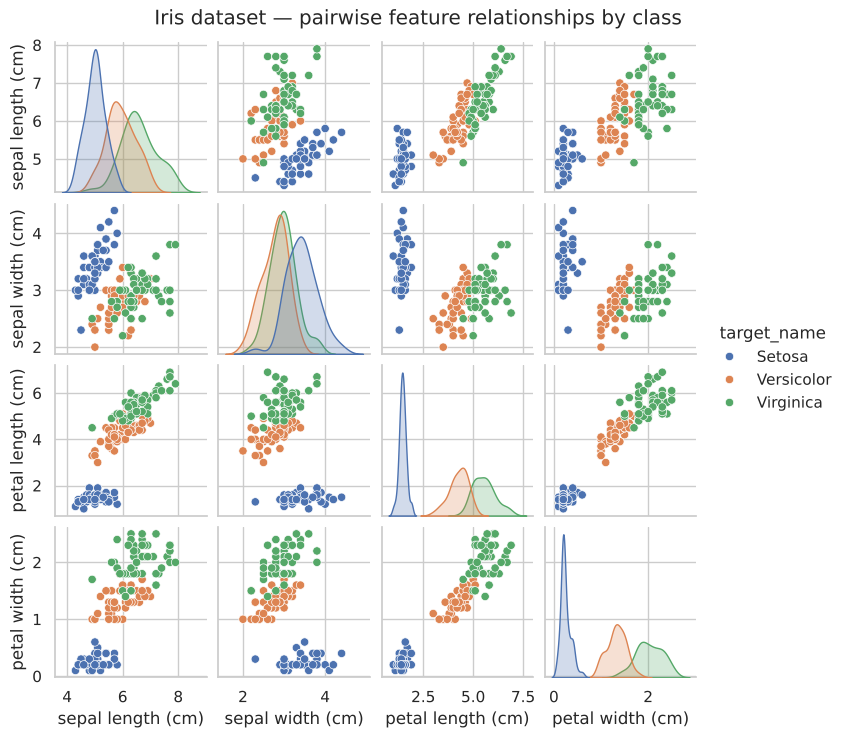

In [10]:
target_names = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
dfi_plot = dfi.copy()
dfi_plot['target_name'] = dfi_plot['target'].map(target_names)
g = sns.pairplot(dfi_plot, vars=iris_feature_names, hue='target_name', diag_kind='kde', palette='deep', height=1.8)
g.fig.suptitle("Iris dataset — pairwise feature relationships by class", y=1.02)
plt.show()

Petal length and petal width show the sharpest, most unimodal separation between classes (Setosa splits off almost perfectly; Versicolor/Virginica overlap slightly) — exactly the two features a decision-tree or logistic-regression model leans on most, and the reason multiclass classification on Iris is comparatively easy.

### 2.5 Decision boundaries (OvR vs. multinomial, 2 features)

To visualise a decision boundary we need exactly 2 input dimensions, so we refit both strategies on petal length/width only.

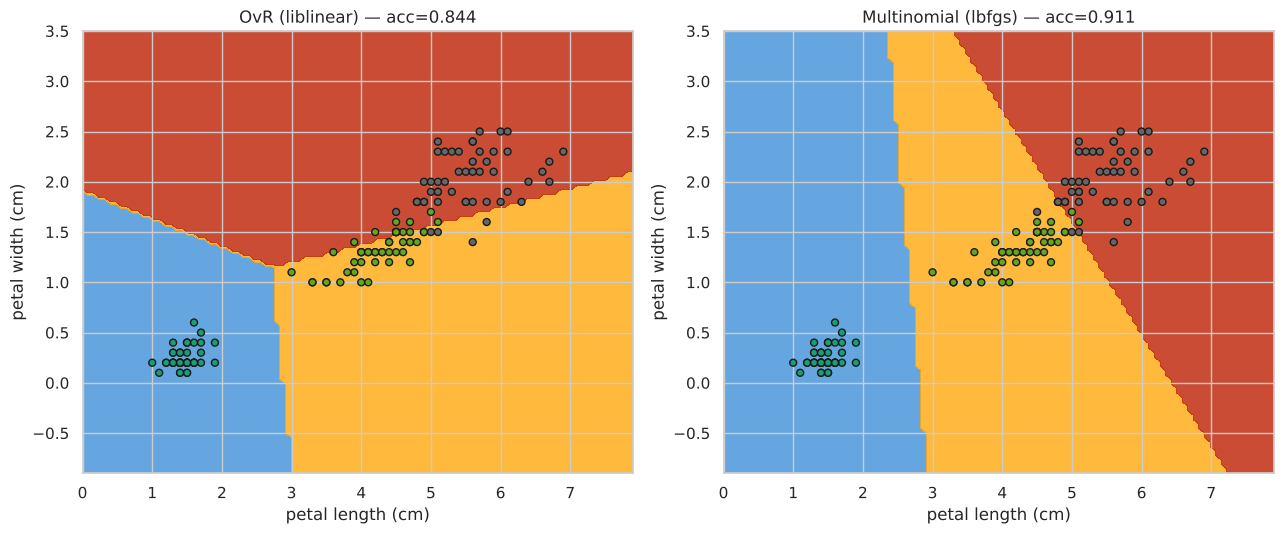

In [11]:
X2 = Xi[:, 2:4]  # petal length, petal width
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, yi, test_size=0.3, random_state=2024)

ovr_2d = OneVsRestClassifier(LogisticRegression(solver='liblinear')).fit(X2_train, y2_train)
multi_2d = LogisticRegression(solver='lbfgs', max_iter=1000).fit(X2_train, y2_train)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, mdl, title in zip(axes, [ovr_2d, multi_2d], ["OvR (liblinear)", "Multinomial (lbfgs)"]):
    disp = DecisionBoundaryDisplay.from_estimator(
        mdl, X2, response_method="predict", cmap=plt.cm.Pastel1, alpha=0.8, ax=ax,
        xlabel=iris_feature_names[2], ylabel=iris_feature_names[3])
    ax.scatter(X2[:, 0], X2[:, 1], c=yi, cmap=plt.cm.Dark2, edgecolors='k', s=25)
    ax.set_title(f"{title} — acc={accuracy_score(y2_test, mdl.predict(X2_test)):.3f}")
plt.tight_layout()
plt.show()

Both strategies draw almost the same boundary on this easy 2-feature problem; the small differences near the Versicolor/Virginica border are exactly where the probability computations in section 2.3 diverge most.

### 2.6 Hands-on checklist
1. Load a multiclass dataset.
2. Fit OvR (`solver='liblinear'`) and multinomial (`solver='lbfgs'` with 3+ classes) logistic regression.
3. Compare accuracy and per-class metrics; check macro vs. weighted averages.
4. Visualise with a pairplot and, for 2 chosen features, a decision-boundary plot.

## 3. Regularization in Logistic Regression

Exactly as in Chapter 5, **L2 (Ridge)** and **L1 (Lasso)** penalties can be added to logistic regression's loss to control overfitting. scikit-learn parameterises strength with `C`, the **inverse** of regularisation strength (small `C` = strong regularisation — the opposite convention from `Ridge`/`Lasso`'s `alpha`).

### 3.1 The book's recipe: Ridge vs. Lasso at C=0.1

In [12]:
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X, y, test_size=0.3, random_state=2024)
scaler_b = StandardScaler()
Xb_train_s = scaler_b.fit_transform(Xb_train)
Xb_test_s = scaler_b.transform(Xb_test)

ridge_model = LogisticRegression(penalty='l2', solver='liblinear', C=0.1).fit(Xb_train_s, yb_train)
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.1).fit(Xb_train_s, yb_train)

acc_ridge = accuracy_score(yb_test, ridge_model.predict(Xb_test_s))
acc_lasso = accuracy_score(yb_test, lasso_model.predict(Xb_test_s))
prec_ridge = precision_score(yb_test, ridge_model.predict(Xb_test_s))
prec_lasso = precision_score(yb_test, lasso_model.predict(Xb_test_s))
rec_ridge = recall_score(yb_test, ridge_model.predict(Xb_test_s))
rec_lasso = recall_score(yb_test, lasso_model.predict(Xb_test_s))

nz_ridge = np.sum(ridge_model.coef_[0] != 0)
nz_lasso = np.sum(lasso_model.coef_[0] != 0)

comparison = pd.DataFrame({
    'model': ['Ridge (L2)', 'Lasso (L1)'],
    'accuracy': [acc_ridge, acc_lasso],
    'precision': [prec_ridge, prec_lasso],
    'recall': [rec_ridge, rec_lasso],
    'non-zero coefficients (of 30)': [nz_ridge, nz_lasso]
})
print(comparison.to_string(index=False))

     model  accuracy  precision  recall  non-zero coefficients (of 30)
Ridge (L2)    0.9825     0.9810  0.9904                             30
Lasso (L1)    0.9649     0.9900  0.9519                              7


As in the book, both regularised models perform well. Lasso drives some coefficients to exactly zero (feature selection); Ridge shrinks all of them but almost never to exactly zero. Whichever of precision/recall differs between the two above reflects a genuine, if small, trade-off — the "right" choice depends on whether false positives (unnecessary biopsies) or false negatives (missed cancers) are costlier in the application.

### 3.2 Coefficient-shrinkage paths vs. C

We sweep `C` across eight orders of magnitude and track every coefficient for both penalties, reproducing the book's visual but adding Lasso's **sparsity count** as a second panel.

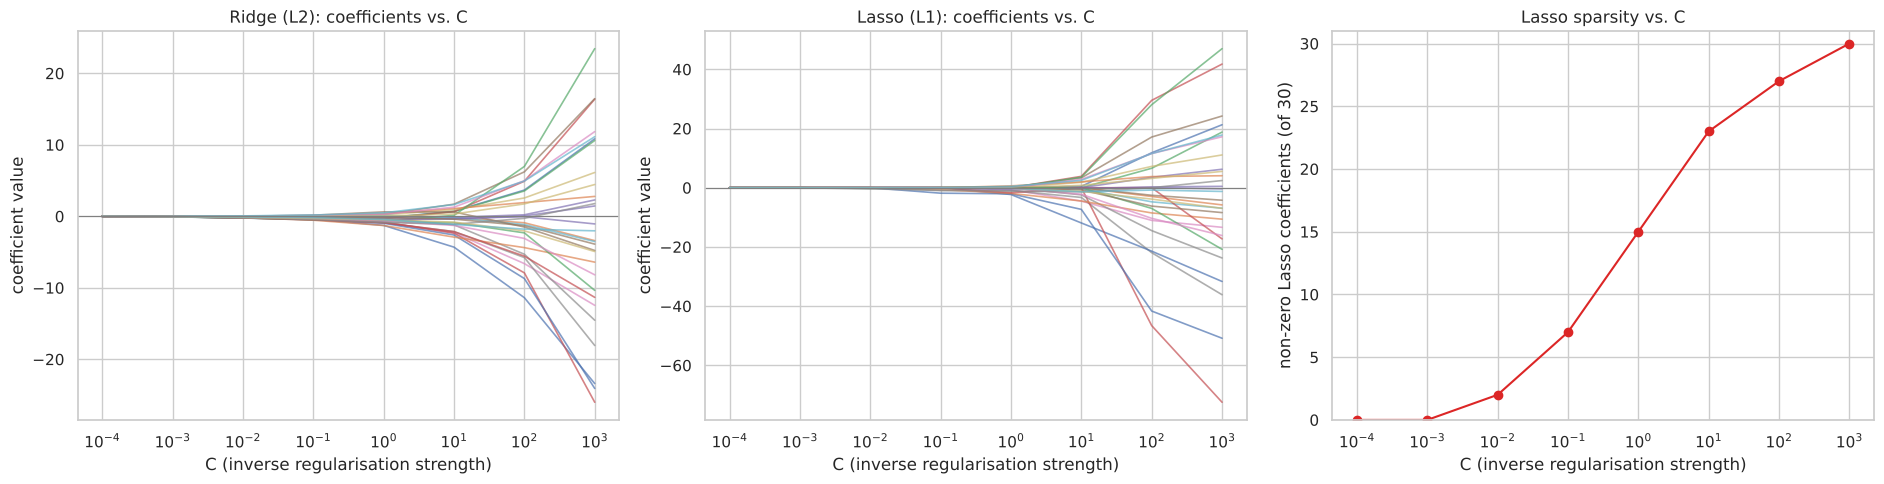

Non-zero Lasso coefficients at each C:
  C=0.0001     -> 0 / 30 non-zero
  C=0.001      -> 0 / 30 non-zero
  C=0.01       -> 2 / 30 non-zero
  C=0.1        -> 7 / 30 non-zero
  C=1          -> 15 / 30 non-zero
  C=10         -> 23 / 30 non-zero
  C=100        -> 27 / 30 non-zero
  C=1000       -> 30 / 30 non-zero


In [13]:
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])

coefs_ridge, coefs_lasso, nnz_lasso = [], [], []
for C in C_values:
    m_r = LogisticRegression(penalty='l2', solver='liblinear', C=C).fit(Xb_train_s, yb_train)
    m_l = LogisticRegression(penalty='l1', solver='liblinear', C=C).fit(Xb_train_s, yb_train)
    coefs_ridge.append(m_r.coef_[0])
    coefs_lasso.append(m_l.coef_[0])
    nnz_lasso.append(np.sum(m_l.coef_[0] != 0))

coefs_ridge = np.array(coefs_ridge)
coefs_lasso = np.array(coefs_lasso)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for i in range(X.shape[1]):
    axes[0].plot(C_values, coefs_ridge[:, i], alpha=0.7, lw=1.2)
    axes[1].plot(C_values, coefs_lasso[:, i], alpha=0.7, lw=1.2)
for ax, title in zip(axes[:2], ["Ridge (L2): coefficients vs. C", "Lasso (L1): coefficients vs. C"]):
    ax.set_xscale('log')
    ax.set_xlabel('C (inverse regularisation strength)')
    ax.set_ylabel('coefficient value')
    ax.set_title(title)
    ax.axhline(0, color='grey', lw=0.8)

axes[2].plot(C_values, nnz_lasso, marker='o', color='#dc2626')
axes[2].set_xscale('log')
axes[2].set_xlabel('C (inverse regularisation strength)')
axes[2].set_ylabel('non-zero Lasso coefficients (of 30)')
axes[2].set_title('Lasso sparsity vs. C')
axes[2].set_ylim(0, 31)
plt.tight_layout()
plt.show()

print("Non-zero Lasso coefficients at each C:")
for c, n in zip(C_values, nnz_lasso):
    print(f"  C={c:<10g} -> {n} / 30 non-zero")

At very small `C` (strong regularisation) all Lasso coefficients are driven to zero and the model predicts the majority class only; as `C` grows the coefficients "switch on" one by one, exactly the sparsity pattern seen with `Lasso`/`LassoCV` in Chapter 5. Ridge's coefficients also shrink toward zero as `C` shrinks but essentially never hit exactly zero, visibly thinner/denser lines in the left panel versus the right.

### 3.3 Hands-on checklist
1. Standardise features — regularisation strength depends on feature scale.
2. Fit `LogisticRegression(penalty='l1'/'l2', solver='liblinear', C=...)`.
3. Tune `C` with cross-validation (`GridSearchCV` or `LogisticRegressionCV`).
4. Compare accuracy, precision, recall and the number of non-zero coefficients (Lasso only).

## 4. Multilabel Classification Concepts

**Multilabel** classification differs from multiclass: an instance can carry **several labels at once** (e.g., a news article tagged both "politics" and "economy"), rather than exactly one of $K$ mutually-exclusive classes.

### 4.1 A synthetic multilabel dataset

As in the book: `make_multilabel_classification(n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024)`.

In [14]:
Xm, ym = make_multilabel_classification(n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024)
dfm = pd.DataFrame(Xm, columns=[f'feature_{i}' for i in range(Xm.shape[1])])
dfm['target'] = list(ym)

Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.3, random_state=2024)
print(f"X shape: {Xm.shape}, y shape: {ym.shape} (5 binary label columns)")
print(f"Average labels per training record: {ym_train.sum(axis=1).mean():.2f}")

X shape: (1000, 20), y shape: (1000, 5) (5 binary label columns)
Average labels per training record: 1.91


`n_labels=2` is only the *average/typical* number of positive labels per record (via a Poisson-like process), not a hard guarantee — some records will have 0, 1, 3, or more positive labels, as the mean above (close to but not exactly 2) shows.

### 4.2 One classifier per label (manual OvR)

In [15]:
models = []
y_pred_all = []
for i in range(ym_train.shape[1]):
    m = LogisticRegression(solver='liblinear')
    m.fit(Xm_train, ym_train[:, i])
    models.append(m)
    y_pred_all.append(m.predict(Xm_test))

y_pred_m = np.array(y_pred_all).T

accuracy_m = accuracy_score(ym_test, y_pred_m)  # "subset accuracy": ALL labels must match exactly
report_m = pd.DataFrame(classification_report(ym_test, y_pred_m, zero_division=1, output_dict=True)).transpose()
print(f"Subset accuracy (exact match across all 5 labels): {accuracy_m:.4f}")
print(report_m.round(3))

Subset accuracy (exact match across all 5 labels): 0.3400
              precision  recall  f1-score  support
0                0.8080  0.8130    0.8110 166.0000
1                0.8010  0.8450    0.8230 181.0000
2                0.6740  0.3330    0.4460  93.0000
3                0.7500  0.1760    0.2860  34.0000
4                0.5750  0.4770    0.5220  88.0000
micro avg        0.7570  0.6530    0.7010 562.0000
macro avg        0.7220  0.5290    0.5770 562.0000
weighted avg     0.7440  0.6530    0.6770 562.0000
samples avg      0.7870  0.7820    0.6800 562.0000


Note `accuracy_score` on a 2-D multilabel array computes **subset accuracy**: a prediction only counts as correct if **every one of the 5 labels** matches exactly, which is a much harder bar than per-label accuracy — this is why the number above looks lower than the per-label precision/recall rows in the report and matches the book's characterisation of multilabel problems as "more challenging."

### 4.3 `MultiOutputClassifier`: the shortcut

scikit-learn offers `MultiOutputClassifier` to avoid the manual loop above. We check it gives identical results.

In [16]:
from sklearn.multioutput import MultiOutputClassifier

moc = MultiOutputClassifier(LogisticRegression(solver='liblinear'))
moc.fit(Xm_train, ym_train)
y_pred_moc = moc.predict(Xm_test)

print(f"Manual-loop subset accuracy:         {accuracy_score(ym_test, y_pred_m):.4f}")
print(f"MultiOutputClassifier subset accuracy: {accuracy_score(ym_test, y_pred_moc):.4f}")
print(f"Predictions identical: {np.array_equal(y_pred_m, y_pred_moc)}")

Manual-loop subset accuracy:         0.3400
MultiOutputClassifier subset accuracy: 0.3400
Predictions identical: True


### 4.4 Label co-occurrence analysis

A co-occurrence matrix shows which labels tend to appear together — useful for spotting label dependencies that a model might exploit or that call for a correlation-aware multilabel method.

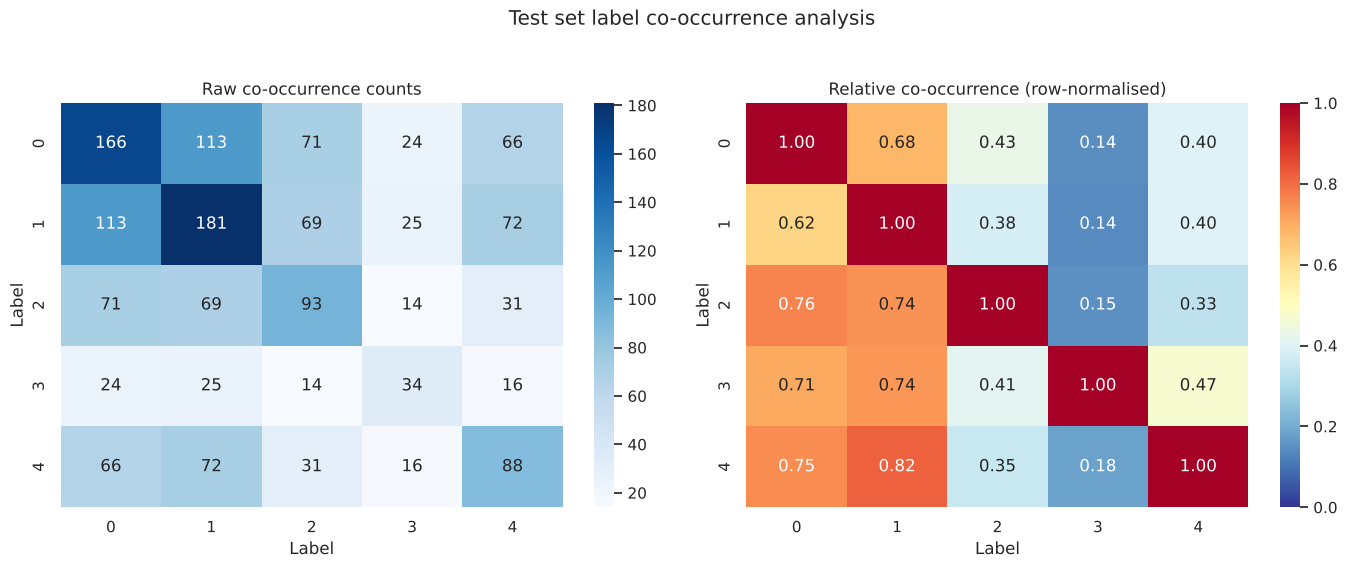

Label statistics:
Total samples: 300
Label frequencies:
  Label 0: 166 samples (55.3%)
  Label 1: 181 samples (60.3%)
  Label 2: 93 samples (31.0%)
  Label 3: 34 samples (11.3%)
  Label 4: 88 samples (29.3%)

Most common label combinations:
  Combination [0 0 0 0 0]: 52 samples (17.3%)
  Combination [0 1 0 0 0]: 34 samples (11.3%)
  Combination [1 1 0 0 0]: 28 samples (9.3%)
  Combination [1 1 1 0 0]: 25 samples (8.3%)
  Combination [1 1 0 0 1]: 24 samples (8.0%)


In [17]:
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    cooccurrence = y.T @ y
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
    sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues', ax=ax1, annot_kws={"fontsize": 12})
    ax1.set_title('Raw co-occurrence counts')
    ax1.set_xlabel('Label')
    ax1.set_ylabel('Label')

    sns.heatmap(relative_cooccurrence, annot=True, fmt='.2f', cmap='RdYlBu_r', ax=ax2,
                annot_kws={"fontsize": 12}, vmin=0, vmax=1)
    ax2.set_title('Relative co-occurrence (row-normalised)')
    ax2.set_xlabel('Label')
    ax2.set_ylabel('Label')
    plt.suptitle(title, y=1.03)
    plt.tight_layout()
    plt.show()

    print("Label statistics:")
    print(f"Total samples: {len(y)}")
    print("Label frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        pct = count / len(y) * 100
        print(f"  Label {i}: {count} samples ({pct:.1f}%)")

    print("\nMost common label combinations:")
    combos, counts = np.unique(y, axis=0, return_counts=True)
    order = np.argsort(-counts)
    for combo, count in zip(combos[order][:5], counts[order][:5]):
        pct = count / len(y) * 100
        print(f"  Combination {combo}: {count} samples ({pct:.1f}%)")

plot_label_cooccurrence(ym_test, "Test set label co-occurrence analysis")

Reading the heatmaps: the **diagonal** of the raw matrix is simply how many times each label is positive in total. Off-diagonal cells show how often two labels co-occur; the relative (right) heatmap turns this into "when label $i$ is present, what fraction of the time is label $j$ also present" — an asymmetric relationship (row $i$ → column $j$ need not equal row $j$ → column $i$) can reveal that label $B$ is essentially a subset of label $A$'s occurrences.

### 4.5 Hands-on checklist
1. Generate or load a multilabel dataset (`y` is a 2-D binary array).
2. Either train one classifier per label manually, or use `MultiOutputClassifier`.
3. Evaluate with per-label precision/recall/F1 (`classification_report` on the full 2-D array) — remember `accuracy_score` here means *all labels correct at once*.
4. Visualise label co-occurrence to understand label dependencies.

## 5. Model Evaluation Metrics

A deeper look at the metrics already used informally above, now with ROC/AUC, on the Breast Cancer dataset with the `liblinear` solver (book's exact recipe).

In [18]:
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X, y, test_size=0.3, random_state=2024)

eval_model = LogisticRegression(solver='liblinear')
eval_model.fit(Xe_train, ye_train)
y_pred_e = eval_model.predict(Xe_test)
y_prob_e = eval_model.predict_proba(Xe_test)[:, 1]

accuracy = accuracy_score(ye_test, y_pred_e)
precision = precision_score(ye_test, y_pred_e)
recall = recall_score(ye_test, y_pred_e)
f1 = f1_score(ye_test, y_pred_e)
fpr, tpr, thresholds = roc_curve(ye_test, y_prob_e)
roc_auc = auc(fpr, tpr)

print(f"Accuracy  {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall    {recall:.2f}")
print(f"F1 Score  {f1:.2f}")
print(f"ROC AUC   {roc_auc:.2f}")
print("\nClassification Report")
print(classification_report(ye_test, y_pred_e))

Accuracy  0.94
Precision 0.94
Recall    0.95
F1 Score  0.95
ROC AUC   0.99

Classification Report
              precision    recall  f1-score   support

           0       0.92      0.91      0.92        67
           1       0.94      0.95      0.95       104

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



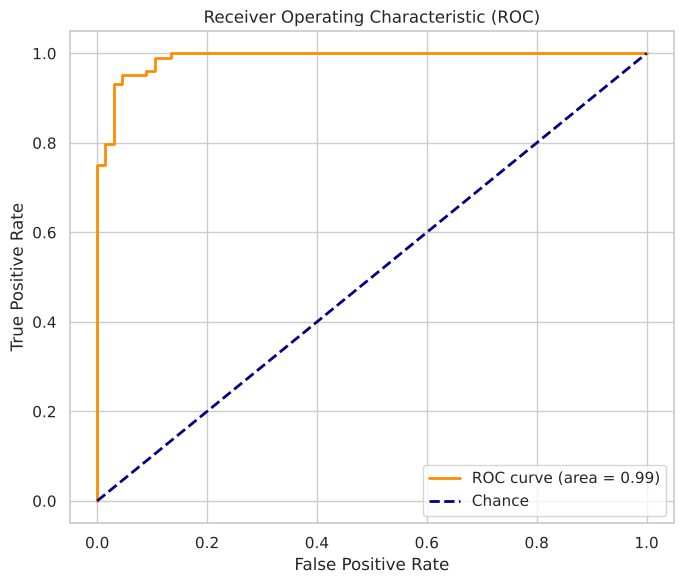

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Receiver Operating Characteristic (ROC)')
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

An AUC close to 1.0 means the model ranks a randomly chosen positive example above a randomly chosen negative example almost all the time — a threshold-independent summary, unlike accuracy/precision/recall, which depend on the 0.5 cutoff.

### 5.1 Precision-recall trade-off across thresholds

Accuracy, precision, and recall above are all computed at the default 0.5 threshold. We show how precision and recall trade off as the threshold moves, which matters whenever 0.5 is not the business-appropriate cutoff (e.g., screening, where recall should dominate).

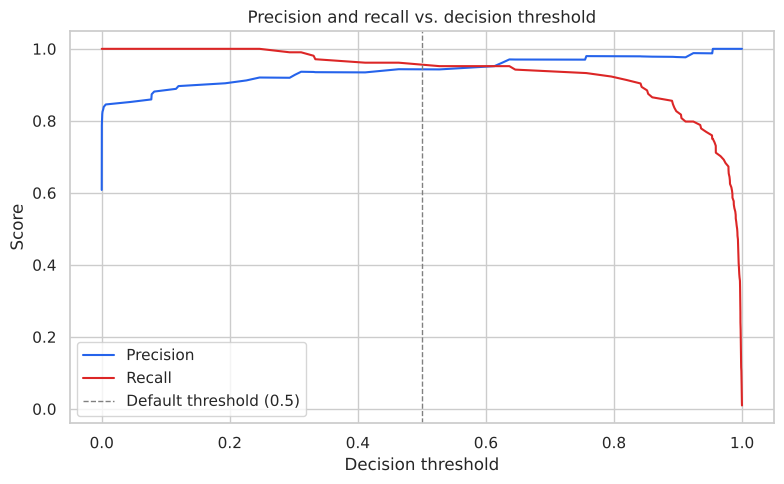

Highest threshold keeping recall >= 0.99: threshold=0.311, precision=0.936, recall=0.990


In [20]:
from sklearn.metrics import precision_recall_curve

prec_curve, rec_curve, pr_thresholds = precision_recall_curve(ye_test, y_prob_e)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr_thresholds, prec_curve[:-1], label='Precision', color='#2563eb')
ax.plot(pr_thresholds, rec_curve[:-1], label='Recall', color='#dc2626')
ax.axvline(0.5, color='grey', ls='--', lw=1, label='Default threshold (0.5)')
ax.set_xlabel('Decision threshold')
ax.set_ylabel('Score')
ax.set_title('Precision and recall vs. decision threshold')
ax.legend()
plt.tight_layout()
plt.show()

# Find the threshold that guarantees recall >= 0.99 (a plausible screening requirement)
target_recall = 0.99
candidates = [(t, p, r) for t, p, r in zip(pr_thresholds, prec_curve[:-1], rec_curve[:-1]) if r >= target_recall]
if candidates:
    best = max(candidates, key=lambda c: c[0])  # highest threshold that still reaches target recall
    print(f"Highest threshold keeping recall >= {target_recall}: threshold={best[0]:.3f}, "
          f"precision={best[1]:.3f}, recall={best[2]:.3f}")
else:
    print(f"No threshold in this split reaches recall >= {target_recall}.")

Lowering the decision threshold below 0.5 trades some precision for higher recall — exactly the lever a clinical application would pull to minimise missed-cancer false negatives, at the cost of more false-positive referrals for further testing.

### 5.2 Hands-on checklist
1. Fit a classifier and get both `predict` (labels) and `predict_proba` (scores).
2. Compute accuracy, precision, recall, F1 at the default threshold.
3. Plot the ROC curve and compute AUC for a threshold-independent summary.
4. Plot precision/recall vs. threshold when the default 0.5 cutoff isn't appropriate for the business problem.

## 6. Practical Exercises with Advanced Logistic Regression

### Exercise 1: A regularized logistic regression model (Lasso vs. Ridge, tuned)

Rather than the book's fixed `C=0.1`, we tune `C` with cross-validation for both penalties and compare.

In [21]:
Xex_train, Xex_test, yex_train, yex_test = train_test_split(X, y, test_size=0.3, random_state=2024)
scaler_ex = StandardScaler()
Xex_train_s = scaler_ex.fit_transform(Xex_train)
Xex_test_s = scaler_ex.transform(Xex_test)

param_grid_C = {'C': np.logspace(-3, 3, 13)}

grid_ridge = GridSearchCV(LogisticRegression(penalty='l2', solver='liblinear', max_iter=5000),
                           param_grid_C, cv=5, scoring='accuracy').fit(Xex_train_s, yex_train)
grid_lasso = GridSearchCV(LogisticRegression(penalty='l1', solver='liblinear', max_iter=5000),
                           param_grid_C, cv=5, scoring='accuracy').fit(Xex_train_s, yex_train)

best_ridge = grid_ridge.best_estimator_
best_lasso = grid_lasso.best_estimator_

results_ex1 = pd.DataFrame({
    'model': ['Ridge (tuned)', 'Lasso (tuned)'],
    'best C': [grid_ridge.best_params_['C'], grid_lasso.best_params_['C']],
    'CV accuracy': [grid_ridge.best_score_, grid_lasso.best_score_],
    'test accuracy': [accuracy_score(yex_test, best_ridge.predict(Xex_test_s)),
                       accuracy_score(yex_test, best_lasso.predict(Xex_test_s))],
    'non-zero coefficients': [np.sum(best_ridge.coef_[0] != 0), np.sum(best_lasso.coef_[0] != 0)]
})
print(results_ex1.to_string(index=False))

        model  best C  CV accuracy  test accuracy  non-zero coefficients
Ridge (tuned)  0.1000       0.9750         0.9825                     30
Lasso (tuned)  0.1000       0.9725         0.9649                      7


### Exercise 2: Evaluating multiclass logistic regression (multinomial, Iris)

Multinomial logistic regression accuracy on Iris test set: 0.9333

              precision  recall  f1-score  support
Setosa           1.0000  1.0000    1.0000  18.0000
Versicolor       0.8460  0.9170    0.8800  12.0000
Virginica        0.9290  0.8670    0.8970  15.0000
accuracy         0.9330  0.9330    0.9330   0.9330
macro avg        0.9250  0.9280    0.9260  45.0000
weighted avg     0.9350  0.9330    0.9340  45.0000


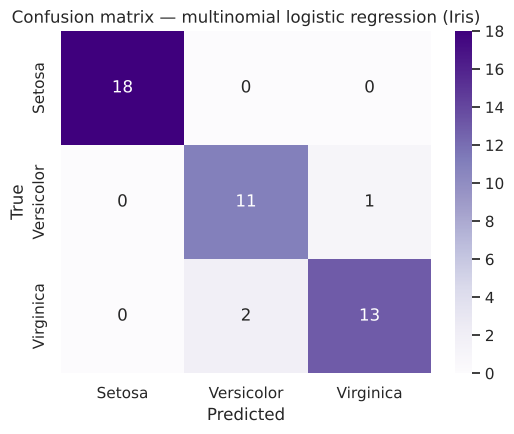

In [22]:
multi_ex = LogisticRegression(solver='lbfgs', max_iter=1000).fit(Xi_train, yi_train)
y_pred_multi_ex = multi_ex.predict(Xi_test)
acc_multi_ex = accuracy_score(yi_test, y_pred_multi_ex)
report_multi_ex = pd.DataFrame(classification_report(
    yi_test, y_pred_multi_ex, target_names=['Setosa', 'Versicolor', 'Virginica'], output_dict=True)).transpose()

print(f"Multinomial logistic regression accuracy on Iris test set: {acc_multi_ex:.4f}\n")
print(report_multi_ex.round(3))

cm_multi = confusion_matrix(yi_test, y_pred_multi_ex)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Setosa', 'Versicolor', 'Virginica'],
            yticklabels=['Setosa', 'Versicolor', 'Virginica'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Confusion matrix — multinomial logistic regression (Iris)')
plt.tight_layout()
plt.show()

### Exercise 3: Visualizing logistic regression decision boundaries (synthetic data)

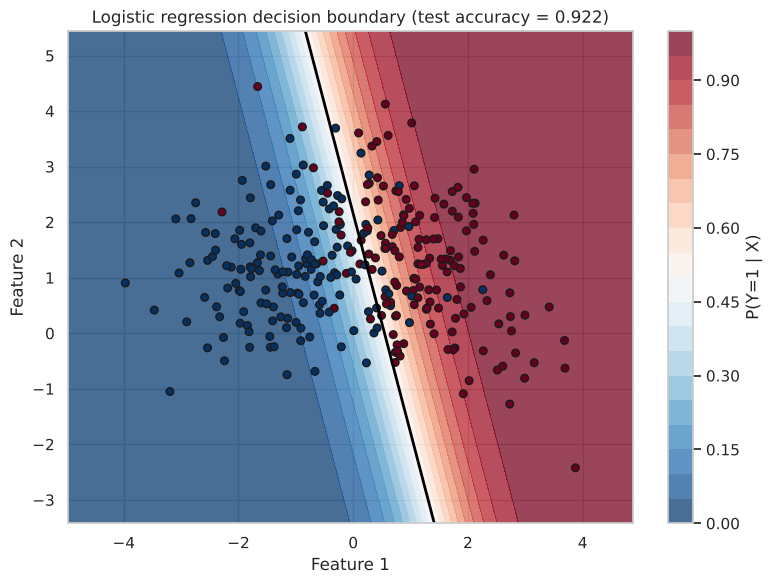

In [23]:
Xs, ys = make_classification(n_samples=300, n_features=2, n_informative=2, n_redundant=0,
                              n_clusters_per_class=1, class_sep=1.2, random_state=2024)
Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, test_size=0.3, random_state=2024)

synth_model = LogisticRegression().fit(Xs_train, ys_train)
acc_synth = accuracy_score(ys_test, synth_model.predict(Xs_test))

x_min, x_max = Xs[:, 0].min() - 1, Xs[:, 0].max() + 1
y_min, y_max = Xs[:, 1].min() - 1, Xs[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
proba_grid = synth_model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
contour = ax.contourf(xx, yy, proba_grid, levels=20, cmap=plt.cm.RdBu_r, alpha=0.75)
ax.contour(xx, yy, proba_grid, levels=[0.5], colors='black', linewidths=2)
ax.scatter(Xs[:, 0], Xs[:, 1], c=ys, cmap=plt.cm.RdBu_r, edgecolors='k', s=30)
plt.colorbar(contour, ax=ax, label='P(Y=1 | X)')
ax.set_title(f"Logistic regression decision boundary (test accuracy = {acc_synth:.3f})")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

The solid black contour at $P=0.5$ is the decision boundary itself; because logistic regression's log-odds is linear in the features, this boundary is always a **straight line** (or hyperplane in higher dimensions) regardless of how the colour gradient curves around it — the curvature in the plot is entirely in the *probability shading*, not the boundary.

## Summary

- **Logistic regression** models $P(Y=1\mid X)$ via the sigmoid of a linear combination of features, fit by maximum likelihood; coefficients are interpretable as log-odds / odds ratios.
- **Multiclass** extensions: One-vs-Rest trains $K$ independent binary classifiers; multinomial (softmax) regression jointly fits all classes so probabilities sum to 1 by construction. They often agree on easy, well-separated data but compute probabilities differently.
- **Regularization** (L1/L2, via `C`) works exactly as with linear Ridge/Lasso from Chapter 5: L2 shrinks smoothly, L1 drives coefficients to exact zero for automatic feature selection; smaller `C` means stronger regularisation (opposite convention to `alpha`).
- **Multilabel classification** predicts several independent binary labels per instance; `accuracy_score` on a 2-D label array means *exact match on all labels*, a much stricter bar than per-label metrics. Label co-occurrence analysis reveals dependencies between labels.
- **Evaluation metrics**: precision/recall/F1 at a chosen threshold, and ROC/AUC as a threshold-independent summary; the right metric (and threshold) depends on the relative cost of false positives vs. false negatives in the application.

This completes Chapter 6. In **Chapter 7**, we move to **support vector machines and kernel methods**, which approach classification from a geometric margin-maximisation perspective instead of a probabilistic one.